# Projeto 2: Clustering de Dados e Detecção de Comunidades em Grafos

**Disciplina:** 5954033 - Algoritmos Avançados de Grafos (2026)

**Docente:** Zhao Liang

**Dataset:** Iris

**Integrantes:**

1. Anna Beatriz Souza e Silva - 13694103
2. Milena Rodrigues Monteiro - 12566157


## Etapa 1 - Preparação dos dados

O dataset Iris foi importado do **UC Irvine Machine Learning Repository**. Suas demais descrições e instruções para importar os dados em Python estão presentes [nesse link](https://archive.ics.uci.edu/dataset/53/iris).

Nesse dataset, cada instância corresponde a uma planta, e seus atributos representam certas descrições de cada uma com um valor contínuo em centímetros.

### Instalando bibliotecas necessárias

In [1]:
%pip install --quiet ucimlrepo scikit-learn networkx matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
# get_ipython().kernel.do_shutdown(restart=True)

### Importando os dados

In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1" # Evita o aviso de memory leak do KMeans

In [3]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np

d = load_iris()
X = pd.DataFrame(d.data, columns=["sepal length", "sepal width", "petal length", "petal width"])
y = pd.DataFrame({"class": ["Iris-" + d.target_names[i] for i in d.target]})
y_gt = np.ravel(y)

### Amostra dos dados

Nessa parte vamos entender os dados que veem no dataset e ver quais são as classes contidas nele.

Considerando aqui, também:

$X$ é um conjunto de dados formado por $n$ objetos:

$$
X = \{x_1, x_2, \ldots, x_n\}
$$

Cada objeto $x_i$ é representado por $d$ atributos (também descritos como colunas aqui):

$$
x_i = (x_{i1}, x_{i2}, \ldots, x_{id})
$$

In [4]:
display(X.sample(5))

,sepal length,sepal width,petal length,petal width
72,6.3,2.5,4.9,1.5
62,6.0,2.2,4.0,1.0
133,6.3,2.8,5.1,1.5
147,6.5,3.0,5.2,2.0
18,5.7,3.8,1.7,0.3


In [5]:
display(y.sample(5))

,class
78,Iris-versicolor
129,Iris-virginica
0,Iris-setosa
140,Iris-virginica
67,Iris-versicolor


In [6]:
# Mostrando todas as classes únicas possíveis do dataset
display(pd.DataFrame({"class": y["class"].unique()}))

,class
0,Iris-setosa
1,Iris-versicolor
2,Iris-virginica


### Análise das classes em `y`

Como visto na célula acima, existem **3 classes possíveis** em `y`:
- Iris-setosa
- Iris-versicolor
- Iris-virginica

Como elas são as classes categóricas, **elas não serão padronizadas ou normalizadas**, já que representam o *Ground Truth* utilizado quando avaliarmos os agrupamentos.

### Padronização dos atributos em `X`

Além disso, temos as seguintes **colunas** (ou atributos) em `X`:
- `sepal length`
- `sepal width`
- `petal length`
- `petal width`

Como o restante do trabalho calcula distâncias, se um atributo tiver maior escala ou variação, ele pode dominar o resultado. A padronização evita isso.

Isso significa que teremos que padronizar os valores das colunas de `X` utilizando a padronização:

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}
$$

onde:

- $\mu_j$ é a média do atributo $j$;
- $\sigma_j$ é o desvio-padrão do atributo $j$.

In [7]:
# Média e desvio-padrão de cada coluna
media = X.mean()
desvio_padrao = X.std()

# Padronização: z = (x - média) / desvio-padrão
X_padronizado = (X - media) / desvio_padrao

display(X_padronizado.head())

,sepal length,sepal width,petal length,petal width
0,-0.897674,1.015602,-1.335752,-1.311052
1,-1.139200,-0.131539,-1.335752,-1.311052
2,-1.380727,0.327318,-1.392399,-1.311052
3,-1.501490,0.097889,-1.279104,-1.311052
4,-1.018437,1.245030,-1.335752,-1.311052


## Etapa 2 - Clustering tradicional (Abordagem 1)

Como pontos em um espaço de atributos, utilizando um algoritmo tradicional de clustering.

$$
X \rightarrow C_{\text{cluster}}
$$

O algoritmo recomendado foi o **K-Means**. O objetivo do K-Means é minimizar a soma das distâncias quadráticas entre cada objeto e o centroide do seu cluster.

#### Escolhendo o do número de clusters utilizados $(K)$

De acordo com a descrição do projeto, foram sugeridos:

- Método do cotovelo (**Elbow Method**);
- **Silhouette Score**;
- Conhecimento prévio sobre o dataset.

#### 1. Conhecimento prévio sobre o dataset

Como visto anteriormente, o dataset Iris tem 3 classes, então poderíamos utilizar $K = 3$ como hipótese. Mas podemos confirmar esse valor com os outros dois métodos.

#### 2. Método do cotovelo (**Elbow Method**)

Esse método testa diversos valores de $K$ (nesse caso, de 2 a 10) no K-Means para calcular a inércia (J), a qual mede o quão espalhados os pontos estão dentro de cada cluster, e com qual valor eles começam a ficar menos espalhados.

A inércia é a soma das distâncias quadráticas entre cada ponto e o centróide do seu cluster.

Com o gráfico da variação da inércia, podemos ver um "cotovelo", o qual indicaria o melhor $K$, porque a partir daquele ponto, criar mais clusters praticamente não mudaria muito o resultado.

##### Preparação do ambiente

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Testar valores de K de 2 a 20
valores_k = range(2, 11)

C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Ro

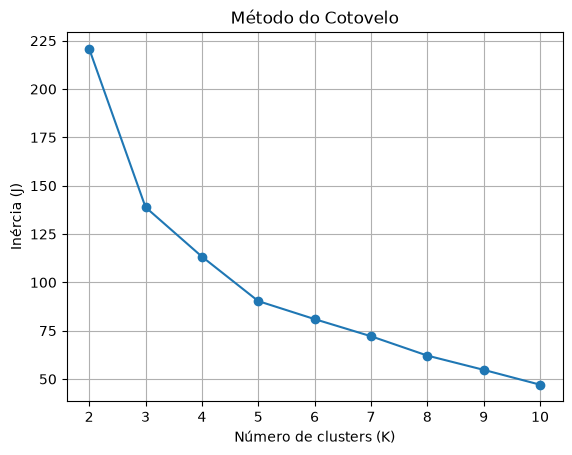

In [10]:
inercia = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    inercia.append(modelo.inertia_)

plt.plot(valores_k, inercia, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (J)")
plt.title("Método do Cotovelo")
plt.grid()
plt.show()

##### Interpretação do método do cotovelo

Observando o gráfico imaginando o formato de um braço, podemos identificar um "cotovelo" (uma dobra) no ponto em que $K = 3$.

Até então, a inércia estava caindo de forma muito brusca, e quando chega em $K = 3$, a queda se suaviza. Por isso, segundo essa métrica, esse seria o número ideal de clusters.

#### 3. Silhouette Score

O Silhouette Score avalia simultaneamente a coesão dos objetos dentro de seus próprios clusters e a separação entre clusters.

Para cada ponto, compara-se a distância média até os pontos do próprio cluster com a distância média até o cluster vizinho mais próximo.

O score varia de -1 a 1: quanto mais próximo de 1, o grupo seria o melhor definido, então ele ajudaria a definir o valor de $K$.

C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\milen\AppData\Ro

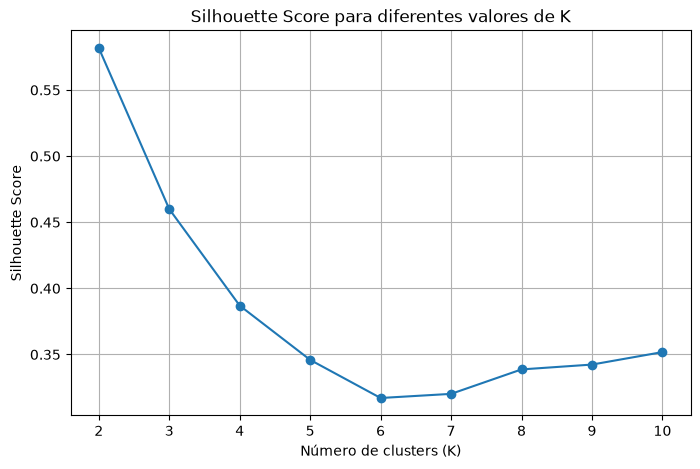

In [11]:
silhouette_scores = []

for k in valores_k:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters_teste = kmeans.fit_predict(X_padronizado)

    score = silhouette_score(
        X_padronizado,
        clusters_teste
    )

    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(
    list(valores_k),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score para diferentes valores de K")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

In [12]:
indice_melhor = silhouette_scores.index(max(silhouette_scores))

k_melhor_silhouette = list(valores_k)[indice_melhor]
melhor_score = silhouette_scores[indice_melhor]

print("Melhor K pelo Silhouette Score:", k_melhor_silhouette)
print("Maior Silhouette Score:", melhor_score)

Melhor K pelo Silhouette Score: 2
Maior Silhouette Score: 0.5817500491982808


#### Valor de K escolhido

| | Método do cotovelo | Silhouette Score | Conhecimento do dataset |
|---|---|---|---|
| **Valor de $K$** | 3 | 2 | 3 |

Pelos 3 métodos sugeridos, o valor de $K$ que mais se repete é $K = 3$.

O método do cotovelo confirmou a hipótese original, enquanto o Silhouette Score sugere $K = 2$.

### Criando o modelo K-Means

In [13]:
from sklearn.metrics import adjusted_rand_score

K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_padronizado)
ari_kmeans_real = adjusted_rand_score(y_gt, clusters)

print("K escolhido:", K)
print("Inércia:", kmeans.inertia_)
print("Silhouette Score:", silhouette_score(X_padronizado, clusters))

K escolhido: 3
Inércia: 138.88835971735145
Silhouette Score: 0.45994823920518635


C:\Users\milen\AppData\Roaming\jupyterlab-desktop\jlab_server\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## Etapa 3 - Construção do grafo de similaridade



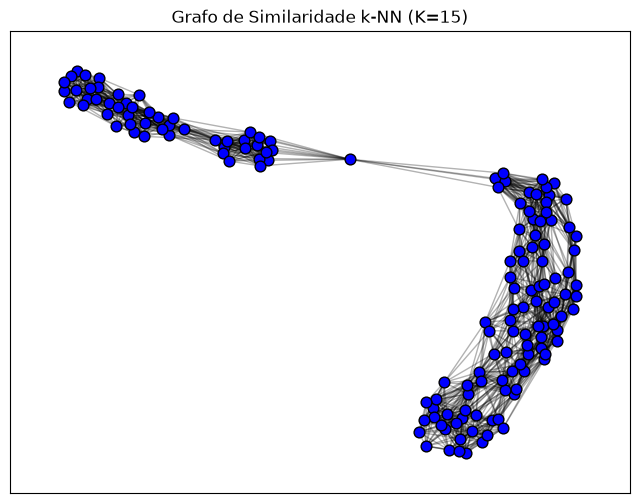

In [14]:
from sklearn.neighbors import kneighbors_graph
import networkx as nx

k_vizinhos = 15  # grafo principal; k=3 fica só na análise de k (Etapa 4)

# Cálculo da matriz adjacente utilizando a distância Euclidiana
matriz_adj = kneighbors_graph(X_padronizado, n_neighbors=k_vizinhos, mode="connectivity",
                              metric="euclidean", include_self=False)

# Grafo base
G_base = nx.from_scipy_sparse_array(matriz_adj)

pos = nx.spring_layout(G_base, seed=42)

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G_base, pos, node_size=60, node_color="blue", edgecolors="k")
nx.draw_networkx_edges(G_base, pos, alpha=0.3)
plt.title(f"Grafo de Similaridade k-NN (K={k_vizinhos})")
plt.show()

### Pesos das arestas

Utilizando uma função de similaridade Gaussiana para ponderar o grafo:

$$
w_{ij} =
\exp\left(
-\frac{d(x_i,x_j)^2}{2\sigma^2}
\right)
$$

Dessa forma, objetos muito semelhantes terão pesos de conexão maiores.

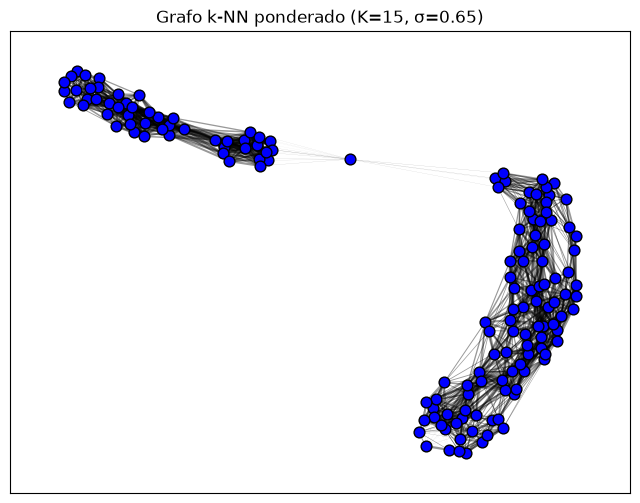

In [15]:
def construir_grafo(X, k):
    # Matriz armazenando as distâncias Euclidianas
    matriz_dist = kneighbors_graph(X, n_neighbors=k, mode="distance",
                                   metric="euclidean", include_self=False)

    # Sigma: média das distâncias das arestas (heurística)
    sigma = matriz_dist.data.mean()

    # Similaridade Gaussiana: w = exp(-d² / (2σ²))
    matriz_pesos = matriz_dist.copy()
    matriz_pesos.data = np.exp(-(matriz_dist.data ** 2) / (2 * sigma ** 2))

    # Grafo ponderado
    return nx.from_scipy_sparse_array(matriz_pesos), sigma

G_peso, sigma = construir_grafo(X_padronizado, k_vizinhos)

# Visualização: espessura proporcional ao peso
pesos = [d["weight"] for _, _, d in G_peso.edges(data=True)]

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G_peso, pos, node_size=60, node_color="blue", edgecolors="k")
nx.draw_networkx_edges(G_peso, pos, width=np.array(pesos) * 2, alpha=0.4)
plt.title(f"Grafo k-NN ponderado (K={k_vizinhos}, σ={sigma:.2f})")
plt.show()

## Etapa 4 - Detecção de comunidades

Aplicando um algoritmo de detecção de comunidades dentre as sugestões, o escolhido foi **Label Propagation**.


In [16]:
import random
import numpy as np
from collections import defaultdict, Counter

def label_propagation(G, max_iter=100, seed=42, weight="weight"):
    rng = random.Random(seed)
    labels = {node: node for node in G.nodes()}
    nodes = list(G.nodes())

    for iteracao in range(max_iter):
        rng.shuffle(nodes)
        mudou = False

        for node in nodes:
            vizinhos = list(G.neighbors(node))
            if not vizinhos:
                continue

            contagem = Counter()
            for v in vizinhos:
                peso = G[node][v].get(weight, 1) if weight else 1
                contagem[labels[v]] += peso

            max_votos = max(contagem.values())
            candidatos = [rot for rot, freq in contagem.items() if freq == max_votos]

            if labels[node] in candidatos:
                continue

            labels[node] = rng.choice(candidatos)
            mudou = True

        if not mudou:
            break

    return labels

#### Cálculo das comunidades

In [17]:
# Label Propagation no grafo ponderado G_peso
labels_dict = label_propagation(G_peso, seed=42)

# Agrupa os vértices por comunidade (maiores primeiro)
grupos = defaultdict(set)
for node, rotulo in labels_dict.items():
    grupos[rotulo].add(node)
comunidades = sorted(grupos.values(), key=len, reverse=True)

# Rótulos 0..n-1 (0 = maior comunidade)
rotulos_comunidades = {v: i for i, com in enumerate(comunidades) for v in com}

# Modularidade
Q = nx.community.modularity(G_peso, comunidades, weight="weight")

print(f"Número de comunidades: {len(comunidades)} | Modularidade Q = {Q:.3f}")
for i, com in enumerate(comunidades):
    print(f"  Comunidade {i}: {len(com)} vértices")

Número de comunidades: 5 | Modularidade Q = 0.568
  Comunidade 0: 80 vértices
  Comunidade 1: 33 vértices
  Comunidade 2: 18 vértices
  Comunidade 3: 17 vértices
  Comunidade 4: 2 vértices


#### Visualização do Label Propagation

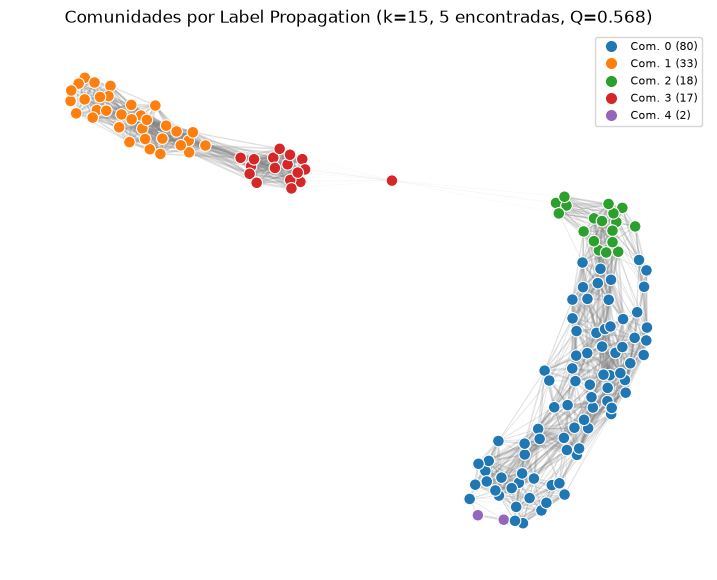

In [18]:
# Visualização: só as N_DESTAQUE maiores comunidades são coloridas, o resto fica em cinza
N_DESTAQUE = 7
cmap_obj = plt.get_cmap("tab10")
COR_RESTO = "lightgray"

n_com = len(comunidades)
cores = [cmap_obj(rotulos_comunidades[v]) if rotulos_comunidades[v] < N_DESTAQUE else COR_RESTO
         for v in G_peso.nodes()]
pesos = np.array([d["weight"] for _, _, d in G_peso.edges(data=True)])

plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(G_peso, pos, width=pesos * 2, alpha=0.25, edge_color="gray")
nx.draw_networkx_nodes(G_peso, pos, node_color=cores,
                       node_size=70, edgecolors="white", linewidths=0.8)

# Legenda com o tamanho de cada comunidade destacada
from matplotlib.lines import Line2D
legenda = [Line2D([0], [0], marker="o", color="w", markersize=9,
                  markerfacecolor=cmap_obj(i), label=f"Com. {i} ({len(comunidades[i])})")
           for i in range(min(N_DESTAQUE, n_com))]
n_resto = n_com - N_DESTAQUE
if n_resto > 0:
    n_nos_resto = sum(len(c) for c in comunidades[N_DESTAQUE:])
    legenda.append(Line2D([0], [0], marker="o", color="w", markersize=9,
                          markerfacecolor=COR_RESTO,
                          label=f"Outras {n_resto} ({n_nos_resto} vértices)"))
plt.legend(handles=legenda, loc="best", fontsize=8)

plt.title(f"Comunidades por Label Propagation (k={k_vizinhos}, {n_com} encontradas, Q={Q:.3f})")
plt.axis("off")
plt.show()


### Avaliação por modularidade

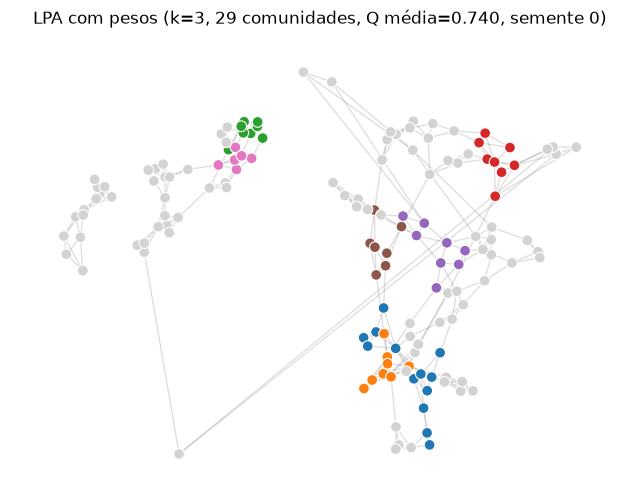

k=3 | Comunidades: 29.0±0.9 | Q=0.740±0.011 | ARI(real)=0.121±0.007 | ARI(K-Means)=0.118±0.005


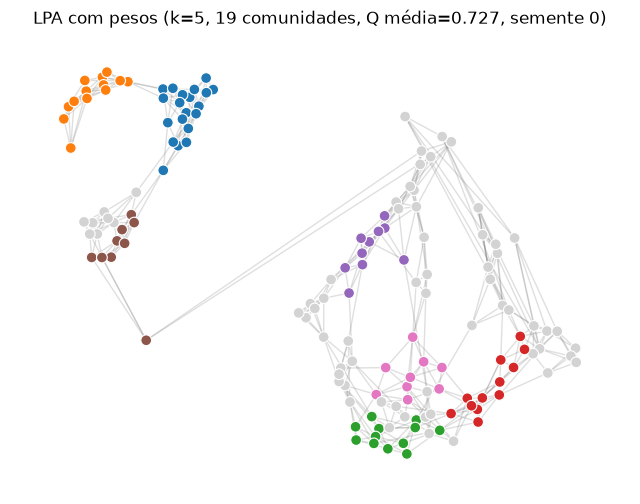

k=5 | Comunidades: 19.4±1.5 | Q=0.727±0.014 | ARI(real)=0.220±0.019 | ARI(K-Means)=0.225±0.017


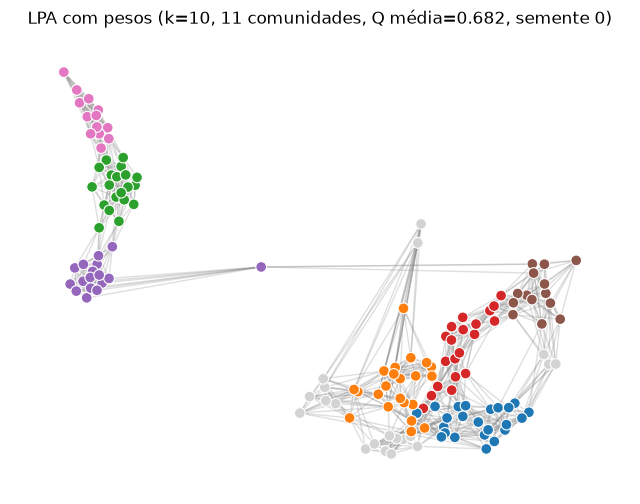

k=10 | Comunidades: 10.5±1.1 | Q=0.682±0.009 | ARI(real)=0.349±0.023 | ARI(K-Means)=0.362±0.033


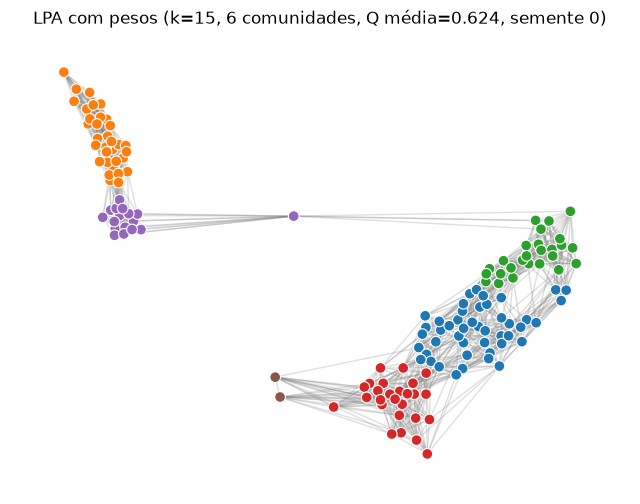

k=15 | Comunidades: 6.6±1.1 | Q=0.624±0.021 | ARI(real)=0.476±0.052 | ARI(K-Means)=0.489±0.052


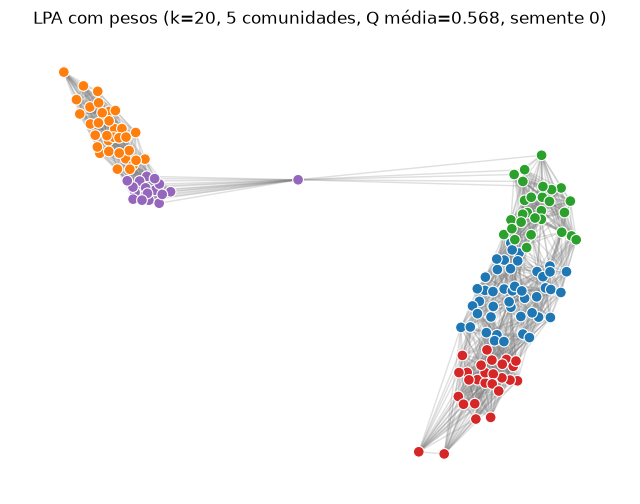

k=20 | Comunidades: 4.1±0.8 | Q=0.568±0.021 | ARI(real)=0.545±0.077 | ARI(K-Means)=0.571±0.079


In [19]:
SEMENTES = list(range(10))
USAR_PESOS = True   # True: grafo gaussiano (construir_grafo) | False: k-NN sem pesos
N_DESTAQUE = 7

k_variacoes = [3, 5, 10, 15, 20]

def avaliar_lpa(G, seed):
    """Roda o LPA e devolve comunidades (maiores primeiro), Q e rótulos 0..n-1."""
    labels_dict = label_propagation(G, seed=seed,
                                    weight="weight" if USAR_PESOS else None)
    grupos = defaultdict(set)
    for no, rot in labels_dict.items():
        grupos[rot].add(no)
    comunidades_var = sorted(grupos.values(), key=len, reverse=True)

    if len(comunidades_var) > 1 and G.number_of_edges() > 0:
        Q = nx.community.modularity(G, comunidades_var, weight="weight")
    else:
        Q = 0.0

    rotulos = np.zeros(G.number_of_nodes(), dtype=int)
    for i, com in enumerate(comunidades_var):
        for v in com:
            rotulos[v] = i
    return comunidades_var, Q, rotulos


# Médias sobre as sementes (mantêm os nomes usados nas células seguintes)
modularidades, ari_lpa_kmeans, ari_lpa_real, num_comunidades_k = {}, {}, {}, {}
# Desvios-padrão
mod_std, ari_km_std, ari_real_std, ncom_std = {}, {}, {}, {}
exemplos = {}   # resultado da 1ª semente, só para plotar

for k_var in k_variacoes:
    if USAR_PESOS:
        G_var, sigma_var = construir_grafo(X_padronizado, k_var)
    else:
        G_var = nx.from_scipy_sparse_array(
            kneighbors_graph(X_padronizado, n_neighbors=k_var, mode="connectivity",
                             metric="euclidean", include_self=False))

    qs, ncs, ari_km, ari_re = [], [], [], []
    for s in SEMENTES:
        com, Q_s, rotulos = avaliar_lpa(G_var, s)
        qs.append(Q_s)
        ncs.append(len(com))
        ari_km.append(adjusted_rand_score(clusters, rotulos))
        ari_re.append(adjusted_rand_score(y_gt, rotulos))
        if s == SEMENTES[0]:
            exemplos[k_var] = (G_var, com, rotulos)

    modularidades[k_var],     mod_std[k_var]      = np.mean(qs),     np.std(qs)
    num_comunidades_k[k_var], ncom_std[k_var]     = np.mean(ncs),    np.std(ncs)
    ari_lpa_kmeans[k_var],    ari_km_std[k_var]   = np.mean(ari_km), np.std(ari_km)
    ari_lpa_real[k_var],      ari_real_std[k_var] = np.mean(ari_re), np.std(ari_re)

    # Plot (1ª semente): só as maiores comunidades coloridas
    G_plot, com_plot, rot_plot = exemplos[k_var]
    cmap_obj = plt.get_cmap("tab10")
    cores_k = [cmap_obj(r) if r < N_DESTAQUE else "lightgray" for r in rot_plot]
    pos_rede = nx.spring_layout(G_plot, seed=42)

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G_plot, pos_rede, alpha=0.25, edge_color="gray")
    nx.draw_networkx_nodes(G_plot, pos_rede, node_color=cores_k,
                           node_size=60, edgecolors="white", linewidths=0.8)
    plt.title(f"LPA {'com' if USAR_PESOS else 'sem'} pesos "
              f"(k={k_var}, {len(com_plot)} comunidades, "
              f"Q média={modularidades[k_var]:.3f}, semente {SEMENTES[0]})")
    plt.axis("off")
    plt.show()

    print(f"k={k_var} | Comunidades: {num_comunidades_k[k_var]:.1f}±{ncom_std[k_var]:.1f} | "
          f"Q={modularidades[k_var]:.3f}±{mod_std[k_var]:.3f} | "
          f"ARI(real)={ari_lpa_real[k_var]:.3f}±{ari_real_std[k_var]:.3f} | "
          f"ARI(K-Means)={ari_lpa_kmeans[k_var]:.3f}±{ari_km_std[k_var]:.3f}")


## Etapa 5 - Comparação entre clustering e detecção de comunidades

Comparando a partição obtida pelo clustering:
$
C_{\text{cluster}}
$

Com a partição obtida pela detecção de comunidades:
$
C_{\text{community}}
$

Com a métrica recomendada: **Adjusted Rand Index (ARI)**.

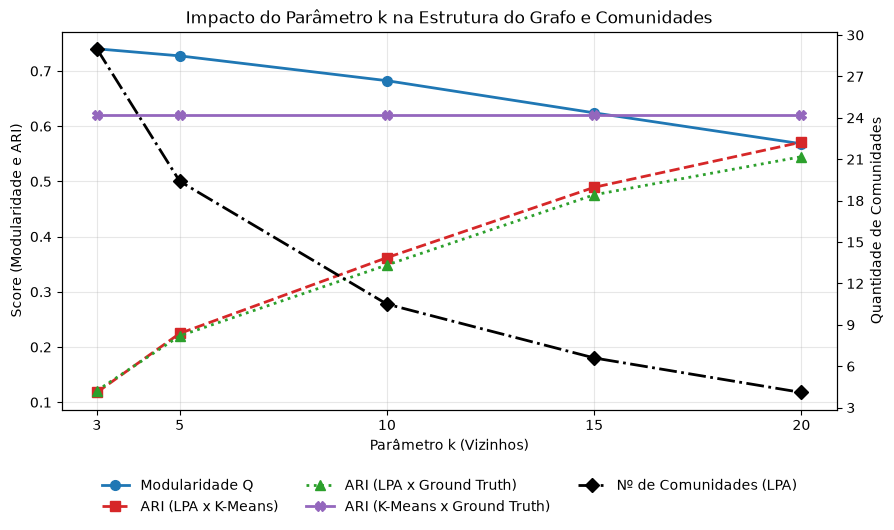

In [20]:
# Gráfico comparativo de métricas
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(k_variacoes, [modularidades[k] for k in k_variacoes], marker="o",
         linestyle="-", color="tab:blue", linewidth=2, markersize=7, label="Modularidade Q")
ax1.plot(k_variacoes, [ari_lpa_kmeans[k] for k in k_variacoes], marker="s", linestyle="--",
         color="tab:red", linewidth=2, markersize=7, label="ARI (LPA x K-Means)")
ax1.plot(k_variacoes, [ari_lpa_real[k] for k in k_variacoes], marker="^", linestyle=":",
         color="tab:green", linewidth=2, markersize=7, label="ARI (LPA x Ground Truth)")
ax1.plot(k_variacoes, [ari_kmeans_real] * len(k_variacoes), marker="X", linestyle="-",
         color="tab:purple", linewidth=2, markersize=7, label="ARI (K-Means x Ground Truth)")

ax1.set_title("Impacto do Parâmetro k na Estrutura do Grafo e Comunidades")
ax1.set_xlabel("Parâmetro k (Vizinhos)")
ax1.set_ylabel("Score (Modularidade e ARI)")
ax1.set_xticks(k_variacoes)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(k_variacoes, [num_comunidades_k[k] for k in k_variacoes], marker="D", 
         linestyle="-.", color="black", linewidth=2, markersize=7, 
         label="Nº de Comunidades (LPA)")
ax2.set_ylabel("Quantidade de Comunidades")
ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

linhas_1, labels_1 = ax1.get_legend_handles_labels()
linhas_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(linhas_1 + linhas_2, labels_1 + labels_2, loc="upper center",
           bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.subplots_adjust(bottom=0.25)
plt.show()

In [21]:
print("ARI (K-Means x Ground Truth):", adjusted_rand_score(np.ravel(y), np.ravel(clusters)))
print("ARI LPA x K-Means:    ", ari_lpa_kmeans)
print("ARI LPA x Ground Truth:", ari_lpa_real)

ARI (K-Means x Ground Truth): 0.6201351808870379
ARI LPA x K-Means:     {3: np.float64(0.11773917313880855), 5: np.float64(0.22467551535101532), 10: np.float64(0.3619257822742711), 15: np.float64(0.48928137372515257), 20: np.float64(0.5710915971563282)}
ARI LPA x Ground Truth: {3: np.float64(0.12093485655323746), 5: np.float64(0.2202450976075685), 10: np.float64(0.3486431174168015), 15: np.float64(0.47573972717539226), 20: np.float64(0.5447515090374578)}


### Experimento com diferentes valores de $k$

In [22]:
tabela = pd.DataFrame({
    "k": k_variacoes,
    "Nº de comunidades": [f"{num_comunidades_k[k]:.1f} ± {ncom_std[k]:.1f}" for k in k_variacoes],
    "Modularidade Q": [f"{modularidades[k]:.3f} ± {mod_std[k]:.3f}" for k in k_variacoes],
    "ARI (LPA x Real)": [f"{ari_lpa_real[k]:.3f} ± {ari_real_std[k]:.3f}" for k in k_variacoes],
    "ARI (LPA x K-Means)": [f"{ari_lpa_kmeans[k]:.3f} ± {ari_km_std[k]:.3f}" for k in k_variacoes],
})

display(tabela.style.hide(axis="index"))


k,Nº de comunidades,Modularidade Q,ARI (LPA x Real),ARI (LPA x K-Means)
3,29.0 ± 0.9,0.740 ± 0.011,0.121 ± 0.007,0.118 ± 0.005
5,19.4 ± 1.5,0.727 ± 0.014,0.220 ± 0.019,0.225 ± 0.017
10,10.5 ± 1.1,0.682 ± 0.009,0.349 ± 0.023,0.362 ± 0.033
15,6.6 ± 1.1,0.624 ± 0.021,0.476 ± 0.052,0.489 ± 0.052
20,4.1 ± 0.8,0.568 ± 0.021,0.545 ± 0.077,0.571 ± 0.079


In [23]:
for k in k_variacoes:
    G_tmp, _ = construir_grafo(X_padronizado, k)
    print(f"k={k} | arestas={G_tmp.number_of_edges()} | densidade={nx.density(G_tmp):.3f}")

k=3 | arestas=302 | densidade=0.027
k=5 | arestas=493 | densidade=0.044
k=10 | arestas=980 | densidade=0.088
k=15 | arestas=1432 | densidade=0.128
k=20 | arestas=1898 | densidade=0.170


### Discussão do experimento com diferentes valores de $k$

Os resultados abaixo são médias de 10 sementes do Label Propagation (grafo ponderado), conforme a tabela acima.

**Como o aumento de $k$ altera a densidade do grafo?**
A densidade cresce aproximadamente de forma linear com $k$, pois cada vértice passa a ter mais arestas. Com $n = 150$ vértices, o grafo tem 302 arestas (densidade ≈ 0,027) para $k = 3$ e 1898 arestas (densidade ≈ 0,170) para $k = 20$. Como as arestas do k-NN são direcionadas e depois simetrizadas, o grau real de cada vértice é um pouco maior que $k$.

**Como o número de comunidades muda?**
Diminui de forma consistente com o aumento de $k$: cerca de 29 comunidades para $k = 3$, 19 para $k = 5$, 10 para $k = 10$, 7 para $k = 15$ e 4 para $k = 20$. Com mais conexões, os rótulos se propagam por regiões maiores antes de se estabilizarem, e comunidades pequenas são absorvidas pelas vizinhas.

**O que acontece quando $k$ é muito pequeno?**
O grafo fica esparso e o Label Propagation estaciona em mínimos locais, produzindo muitas comunidades pequenas. Para $k = 3$ o grafo tem apenas 2 componentes conexas, então a fragmentação (~29 comunidades) vem do algoritmo e não de um grafo desconexo. A modularidade é a mais alta (Q ≈ 0,74), mas o ARI em relação às classes reais é baixo (≈ 0,12): a partição é fragmentada demais para recuperar as 3 espécies. O Q alto reflete a esparsidade do grafo, e não uma boa separação das classes.

**O que acontece quando $k$ é muito grande?**
O grafo fica denso, as comunidades se fundem e a modularidade cai (Q ≈ 0,57 para $k = 20$), pois as arestas passam a ligar pontos de regiões distintas. Em contrapartida, o ARI aumenta (≈ 0,55 em relação ao ground truth), porque a partição se aproxima das 3 classes. Só testamos até $k = 20$; para valores ainda maiores, espera-se que as comunidades se fundam em poucos grupos grandes, perdendo a separação entre classes parecidas.

**Qual valor de $k$ produz os melhores resultados?**
Depende do critério. A modularidade $Q$ é máxima em $k = 3$, e o ARI (contra o ground truth e contra o K-Means) é máximo em $k = 20$. As duas métricas variam em sentidos opostos: $Q$ mede a qualidade da partição no próprio grafo e favorece muitas comunidades coesas, enquanto o ARI mede a concordância com as classes. Como o objetivo do projeto é comparar clustering e detecção de comunidades, consideramos o ARI o critério principal e destacamos $k = 15$ e $k = 20$ como os melhores valores. O valor $k = 15$ é um compromisso razoável: cerca de 7 comunidades, ARI ≈ 0,48 e Q ≈ 0,62.

**Observações.**
- O Label Propagation é estocástico, e o desvio-padrão do ARI chega a ≈ 0,08 para $k = 20$; diferenças pequenas entre $k = 15$ e $k = 20$ devem ser interpretadas com cautela.
- Mesmo no melhor caso, o ARI do Label Propagation (≈ 0,55) fica abaixo do K-Means (≈ 0,62). As classes versicolor e virginica se sobrepõem no espaço de atributos, e o método baseado em vizinhança tende a fundi-las ou fragmentá-las.
- Como $\sigma$ é calculado a partir da média das distâncias das arestas, ele muda com $k$, e os pesos gaussianos não são diretamente comparáveis entre valores de $k$.
